# Самостоятельная работа: кластеризация — выбор алгоритма, проверка гипотез и устойчивость

## Цель работы

Научиться не только запускать алгоритмы, но и **объяснять**, почему они дают разные разбиения, когда метрики вводят в заблуждение и насколько результат устойчив к настройкам и предобработке.

В работе используются синтетические данные и реальный набор `Wine` из scikit-learn. 

**Правила сдачи:** выполнить код, оставить графики и таблицы, ответить на вопросы в Markdown-ячейках «Ответ». Где требуется сравнение — привести численные результаты. Итоговый вывод обязателен. Не использовать истинные классы при настройке неконтролируемой кластеризации: их можно применять **только для внешней оценки после выбора модели**, если указано явно.

**Оценивание:** 1 — 10, 2 — 15, 3 — 15, 4 — 15, 5 — 10, 6 — 15, 7 — 20; бонус — до 15.

## Подготовка среды

Нужны `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`. Зафиксируйте случайное зерно для воспроизводимости.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score
)
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import ParameterGrid

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 30)
print('Среда готова')

Среда готова


## Справочные функции

Эти функции можно использовать в заданиях. Метрики не вычисляются, если разбиение вырождено. **Важно:** `-1` в DBSCAN — метка шума, а не обычный кластер. При интерпретации метрик отдельно указывайте, как учтён шум.

In [3]:
def plot_clusters(X, labels, title='', ax=None):
    """Показывает первые две координаты уже двумерного X; шум (-1) — крестики."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4.5))
    X = np.asarray(X)
    labels = np.asarray(labels)
    for lbl in np.unique(labels):
        mask = labels == lbl
        if lbl == -1:
            ax.scatter(X[mask, 0], X[mask, 1], c='gray', marker='x', s=25,
                       alpha=0.7, label='шум')
        else:
            ax.scatter(X[mask, 0], X[mask, 1], s=12, alpha=.8, label=f'кластер {lbl}')
    ax.set_title(title)
    ax.set_xlabel('Признак 1')
    ax.set_ylabel('Признак 2')
    return ax


def score_partition(X, labels, exclude_noise=False):
    """Silhouette и доля шума; укажите выбранную политику учета шума."""
    X, labels = np.asarray(X), np.asarray(labels)
    noise_fraction = float(np.mean(labels == -1))
    mask = (labels != -1) if exclude_noise else np.ones(len(labels), dtype=bool)
    X_use, labels_use = X[mask], labels[mask]
    n_clusters = len(set(labels) - {-1})
    valid = 2 <= len(np.unique(labels_use)) < len(labels_use)
    return {
        'n_clusters_wo_noise': n_clusters,
        'noise_fraction': noise_fraction,
        'silhouette': silhouette_score(X_use, labels_use) if valid else np.nan,
        'n_scored': int(mask.sum()),
    }

---
## Задание 1. Геометрия кластеров и предположения алгоритмов (10 баллов)

Сгенерированы **три разные структуры данных**. Для каждого набора примените K-Means (`k=2` для `moons`, `k=4` для `blobs`, `k=3` для `uneven`), AgglomerativeClustering с `linkage='ward'` и DBSCAN с разумными параметрами. Изобразите полученные разбиения в виде сетки **3 × 3**.

**Вопросы:**
1. На каких данных K-Means ошибается из-за формы кластеров?
2. Почему у DBSCAN может не получиться выделить группы разной плотности одним значением `eps`?
3. Чем решение Ward напоминает K-Means и в чём отличается?

**Подсказка:** начните с `eps` около 0.2–0.4 для `moons`; для остальных подбирайте масштаб по графикам.

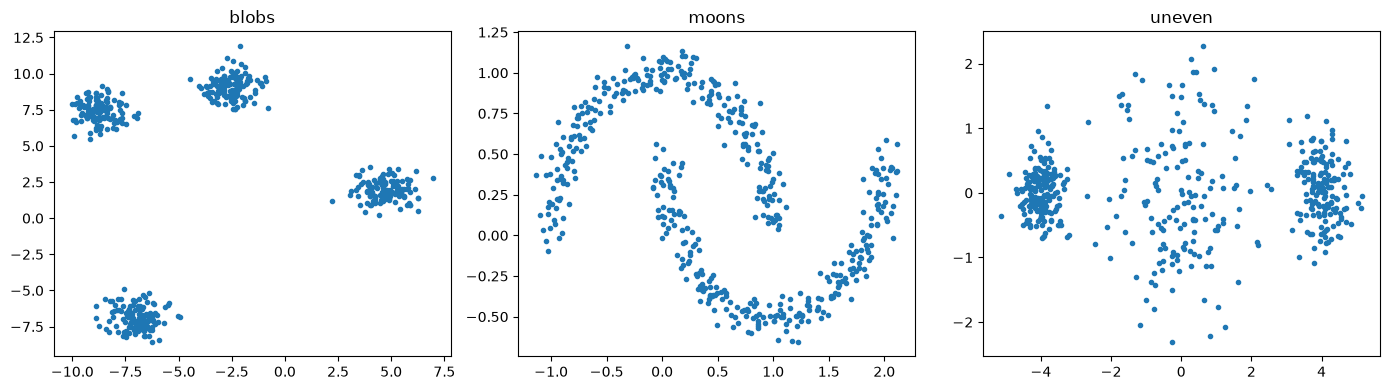

In [4]:
X_blobs, y_blobs = make_blobs(n_samples=500, centers=4, cluster_std=0.75,
                               random_state=RANDOM_STATE)
X_moons, y_moons = make_moons(n_samples=500, noise=0.07, random_state=RANDOM_STATE)
X_uneven, y_uneven = make_blobs(n_samples=[180, 160, 160],
                               centers=[[-4, 0], [0, 0], [4, 0]],
                               cluster_std=[0.35, 1.0, 0.45],
                               random_state=RANDOM_STATE)
datasets = {'blobs': X_blobs, 'moons': X_moons, 'uneven': X_uneven}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, X) in zip(axes, datasets.items()):
    ax.scatter(X[:, 0], X[:, 1], s=9)
    ax.set_title(name)
plt.tight_layout()

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


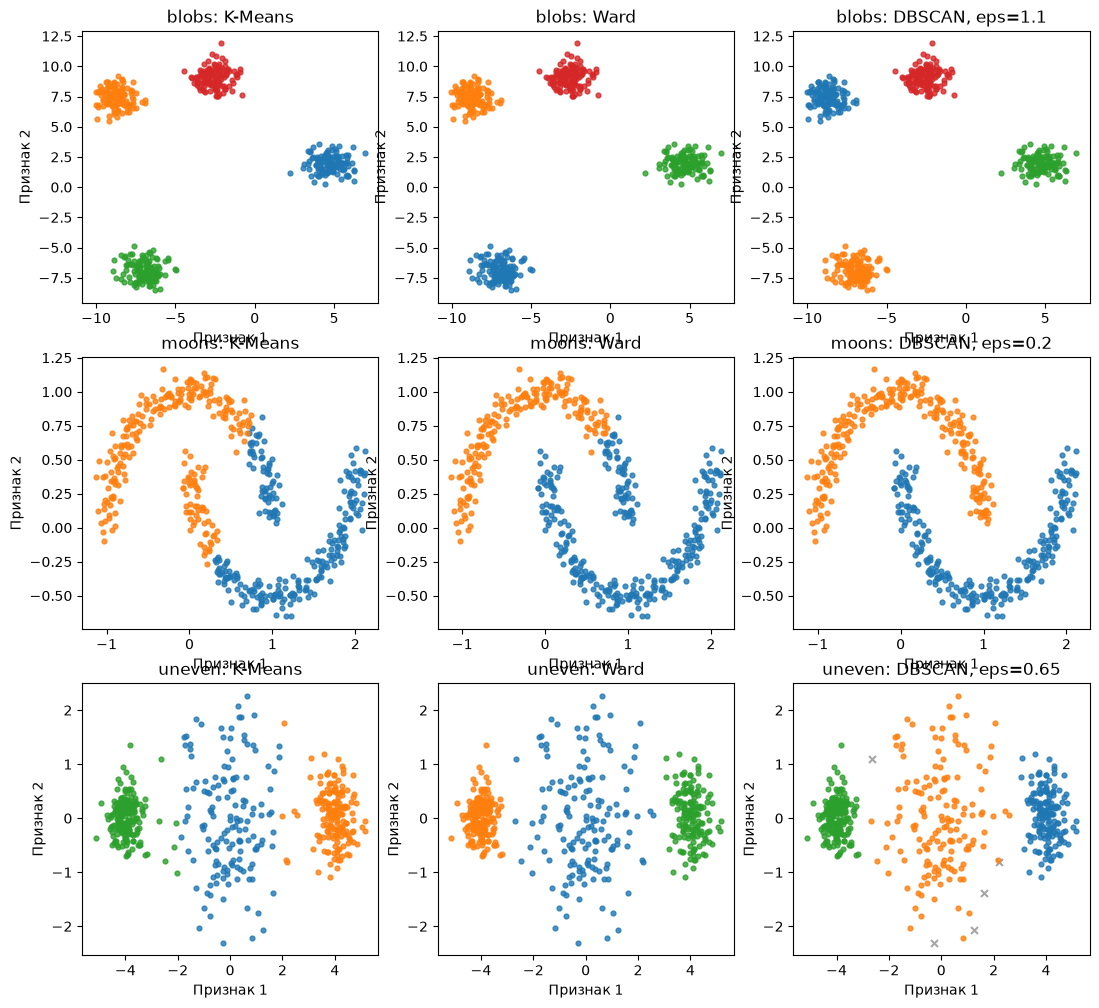

In [5]:
# TODO 1: запустите три алгоритма на каждом наборе,
# отобразите сетку 3x3 и запишите выбранные параметры DBSCAN.
# Не используйте y_blobs/y_moons/y_uneven для обучения или выбора параметров.

cluster_counts = {
    'blobs': 4,
    'moons': 2,
    'uneven': 3
}

parameters = {
    'blobs': (1.1, 5),
    'moons': (0.2, 5),
    'uneven': (0.65, 5)
}

fix, axes = plt.subplots(3, 3, figsize=(13, 12))

for row, (name, X) in enumerate(datasets.items()):
    k = cluster_counts[name]

    labels_kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=RANDOM_STATE,
    ).fit_predict(X)

    labels_agglomerative = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    ).fit_predict(X)

    eps, min_samples = parameters[name]
    labels_dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        
    ).fit_predict(X)

    results = [
        ('K-Means', labels_kmeans),
        ('Ward', labels_agglomerative),
        (f'DBSCAN, eps={eps}', labels_dbscan),
    ]

    for col, (method, labels) in enumerate(results):
        plot_clusters(
            X,
            labels,
            title=f'{name}: {method}',
            ax=axes[row, col]
        )


fig.tight_layout()
plt.show()
    
    


**Ответ к заданию 1:**

1. На moons и немного на uneven. В moons два кластера имеют форму полумесяцев, а K-Means разделяет точки вокруг центров и лучше работает с компактными, примерно округлыми группами. В uneven кластер по центру разбросан по сравнению с другими двумя по бокам поэтому в точках на границах с центром есть путаница из за разници растояний от центров кластеров.
2. DBSCAN считает точки соседями, если расстояние между ними не больше eps. На разреженных участках нужен больший eps, чтобы собрать достаточно соседей; в плотных такой большой радиус может соединить разные группы.
3. Оба метода используют расстояния и обычно хорошо находят компактные группы. Но K-Means перемещает центры кластеров и относит точки к ближайшему центру, а Ward постепенно объединяет ближайшие группы, выбирая слияние с наименьшим увеличением разброса внутри кластеров. Ward не требует случайной инициализации центров.

   Для DBSCAN: eps=1.1 для blobs, 0.2 для moons и 0.65 для uneven
 

---
## Задание 2. Масштабирование и бесполезный признак (15 баллов)

Используйте `X_blobs` и создайте **третий случайный признак**, не связанный с группами, но с большой дисперсией. Сравните K-Means с `k=4` в трёх сценариях:

A. исходные два признака;

B. те же два + «шумовой» признак без масштабирования;

C. три признака после `StandardScaler`.

Для каждого сценария вычислите `silhouette` **в том же пространстве, в котором обучали модель**, и `ARI` относительно `y_blobs` (только как постфактум-проверку). Представьте результаты таблицей.

**Обязательно:** объясните, почему стандартизация не эквивалентна удалению неинформативного признака. Приведите пример, когда масштабирование помогает и когда может навредить.

In [6]:
rng = np.random.default_rng(RANDOM_STATE)
noise_feature = rng.normal(loc=0, scale=40, size=len(X_blobs))
X_augmented = np.column_stack([X_blobs, noise_feature])
X_scaled = StandardScaler().fit_transform(X_augmented)

print('Стандартные отклонения без масштабирования:', X_augmented.std(axis=0).round(2))
print('После StandardScaler:', X_scaled.std(axis=0).round(2))

Стандартные отклонения без масштабирования: [ 5.23  6.28 38.36]
После StandardScaler: [1. 1. 1.]


In [9]:
# TODO 2: обучите 3 модели, соберите DataFrame с колонками:
# scenario, silhouette, ARI, n_features.
# Обратите внимание: silhouette разных пространств не является
# прямой мерой улучшения одной и той же фиксированной геометрии.
scenarios = {
    'A: исходные 2 признака': X_blobs,
    'B: 3 признака, без масштабирования': X_augmented,
    'C: 3 признака, StandardScaler': X_scaled,
}

results = []

for scenario, X in scenarios.items():
    model = KMeans(
        n_clusters=4,
        random_state=RANDOM_STATE,
        n_init=10
    )

    labels = model.fit_predict(X)

    results.append({
        'scenario': scenario,
        'silhouette': silhouette_score(X, labels),
        'ARI': adjusted_rand_score(y_blobs, labels),
        'n_features': X.shape[1],
    })

results_df = pd.DataFrame(results)
results_df.head()

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,scenario,silhouette,ARI,n_features
0,A: исходные 2 признака,0.844188,1.000000,2
1,"B: 3 признака, без масштабирования",0.430665,0.003622,3
2,"C: 3 признака, StandardScaler",0.435826,0.668793,3


**Ответ к заданию 2:**

*Таблица и интерпретация.*

В сценарии A использованы только два исходных признака: силуэт равен 0.844, а ARI  1.000. Это означает, что K-Means нашёл хорошо отделённые группы, совпавшие с метками y_blobs.

В сценарии B добавлен шумовой признак с большим разбросом без масштабирования. ARI упал до 0.004: в пространстве расстояний шумовой признак стал сильно влиять на решение K-Means. Силуэт 0.431 показывает, что найденные группы выглядят относительно компактными в новом пространстве, но они почти не совпадают с известными группами. 

В сценарии C после стандартизации ARI вырос до 0.669. Масштабирование уменьшило доминирование шумового признака по сравнению со сценарием B, но не удалило его: алгоритм всё ещё учитывает все три признака. 

Стандартизация меняет масштаб признака, обычно приводя его среднее к 0, а стандартное отклонение к 1. Удаление признака исключило бы его из расчёта расстояний полностью. Поэтому эти операции не равнозначны: после стандартизации даже неинформативный признак продолжает влиять на K-Means.

Масштабирование может помочь, когда признаки измеряются в разных единицах, например рост в сантиметрах, а доход в тысячах рублей: без обработки признак с большими числовыми значениями может чрезмерно влиять на расстояния. Оно может навредить, если слабый или шумовой признак после масштабирования получает такой же разброс, как полезные признаки, и начинает заметно влиять на расстояния.

---
## Задание 3. Сколько кластеров искать? (15 баллов)

На `X_blobs` обучите K-Means для `k=2, ..., 10`. Постройте **два графика**: `inertia` и `silhouette` как функции `k`. Выберите оптимальное `k` **без обращения к `y_blobs`**. Затем проверьте выбранный вариант внешней метрикой ARI.

Далее искусственно добавьте к исходным данным **50 равномерно распределённых выбросов** и повторите подбор `k`. Сравните результаты.

**Вопросы:** почему `inertia` почти всегда снижается с ростом `k`? Что именно показывает silhouette? Могут ли два критерия предложить разные значения `k`? Почему?

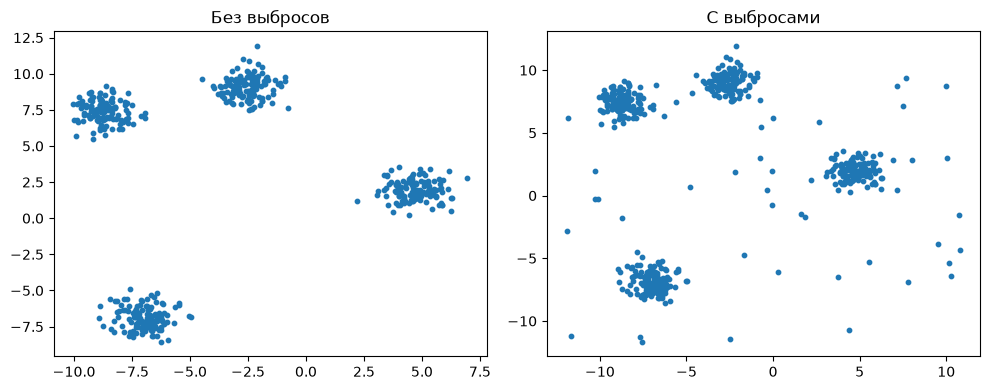

In [10]:
rng = np.random.default_rng(123)
outliers = rng.uniform(low=[-12, -12], high=[12, 12], size=(50, 2))
X_with_outliers = np.vstack([X_blobs, outliers])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], s=10)
axes[0].set_title('Без выбросов')
axes[1].scatter(X_with_outliers[:, 0], X_with_outliers[:, 1], s=10)
axes[1].set_title('С выбросами')
plt.tight_layout()

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

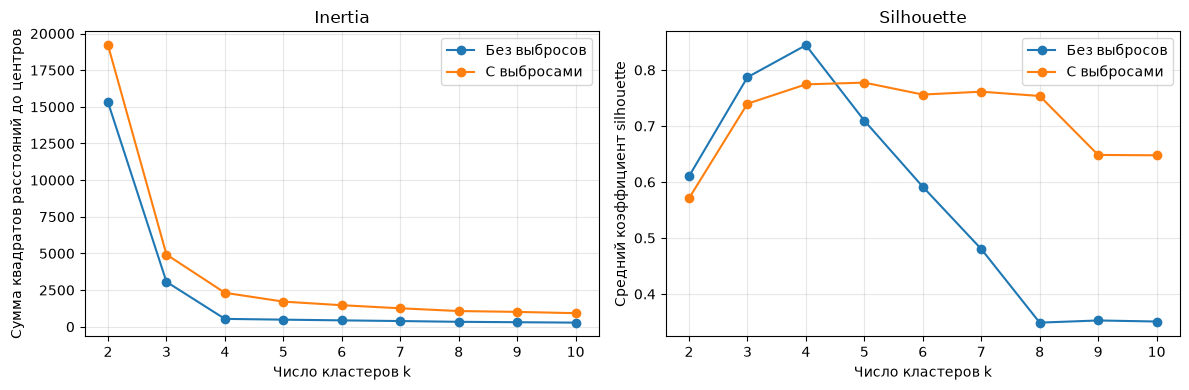

ARI при k=4: 1.0


C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [15]:
# TODO 3: напишите функцию evaluate_kmeans(X, k_values),
# возвращающую DataFrame с k, inertia, silhouette;
# постройте 4 кривые (2 критерия × 2 датасета).
# Не выбирайте k по ARI: это внешняя проверка после выбора.

def evaluate_kmeans(X, k_values):
    rows = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )
        labels = model.fit_predict(X)

        rows.append({
            'k': k,
            'inertia': model.inertia_,
            'silhouette': silhouette_score(X, labels),
        })

    return pd.DataFrame(rows)


k_values = range(2, 11)

scores_blobs = evaluate_kmeans(X_blobs, k_values)
scores_outliers = evaluate_kmeans(X_with_outliers, k_values)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Inertia 
axes[0].plot(
    scores_blobs['k'], scores_blobs['inertia'],
    marker='o', label='Без выбросов'
)
axes[0].plot(
    scores_outliers['k'], scores_outliers['inertia'],
    marker='o', label='С выбросами'
)
axes[0].set_title('Inertia')
axes[0].set_xlabel('Число кластеров k')
axes[0].set_ylabel('Сумма квадратов расстояний до центров')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Silhouette 
axes[1].plot(
    scores_blobs['k'], scores_blobs['silhouette'],
    marker='o', label='Без выбросов'
)
axes[1].plot(
    scores_outliers['k'], scores_outliers['silhouette'],
    marker='o', label='С выбросами'
)
axes[1].set_title('Silhouette')
axes[1].set_xlabel('Число кластеров k')
axes[1].set_ylabel('Средний коэффициент silhouette')
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

labels_selected = KMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10
).fit_predict(X_blobs)

ari_selected = adjusted_rand_score(y_blobs, labels_selected)
print(f'ARI при k=4: {ari_selected}')

**Ответ к заданию 3:**

*Выбранные k, численные аргументы, влияние выбросов.*

Почему inertia почти всегда снижается с ростом k?
Inertia  это сумма квадратов расстояний точек до центров своих кластеров. Когда кластеров больше, точки можно распределить по более мелким группам и приблизить к их центрам. Поэтому inertia обычно уменьшается. Если каждому объекту назначить отдельный кластер, она станет равна нулю, но такое разбиение не будет полезным.

Что показывает silhouette?
Для каждой точки силуэт сравнивает её среднее расстояние до точек своего кластера с расстоянием до ближайшего другого кластера. Он оценивает, насколько кластеры компактны и хорошо отделены. Значение ближе к 1 обычно говорит о хорошем разделении, около 0 о близких или пересекающихся кластерах, отрицательное что некоторые точки могут быть ближе к чужому кластеру.

Могут ли критерии предложить разные значения k? Почему?
Да. Inertia учитывает только расстояния до центров и всегда выигрывает от добавления кластеров, поэтому по ней ищут локоть (место где улучшение становится небольшим). Silhouette оценивает одновременно компактность и отделённость групп и может достигать максимума при другом k. Метрики измеряют разные свойства разбиения, поэтому их расхождение повод рассмотреть графики и обосновать компромисс, а не выбирать число кластеров по одной метрике.

Выбросы увеличили inertia и сделали выбор по silhouette менее ясным. Это показывает, что выбросы могут заметно влиять на K-Means и внутренние метрики. Для исходных данных ARI при выбранном k=4 равен 1.000

---
## Задание 4. DBSCAN: подбор параметров и проблема шума (15 баллов)

Для `X_moons`:

1. Постройте график расстояния до **5-го ближайшего соседа** (с учётом самой точки в `NearestNeighbors`, то есть используйте `n_neighbors=5` и последнюю колонку расстояний). Обоснуйте приблизительное `eps`.
2. Подберите `eps` из диапазона `0.08 ... 0.40` и `min_samples ∈ {3, 5, 10}`. Для каждой комбинации сохраните число кластеров **без шума**, долю шума и силуэт по точкам **без шума** (`exclude_noise=True`).
3. Выберите модель по сочетанию разумного числа кластеров, небольшой доли шума и визуального соответствия геометрии. Не максимизируйте silhouette вслепую.
4. Сравните две версии silhouette: **включая шум как отдельную метку** и **исключая шум**. Объясните, почему обе требуют осторожной интерпретации.

**Условие:** варианты с единственным найденным кластером нельзя объявлять лучшими только из-за неопределённого silhouette.

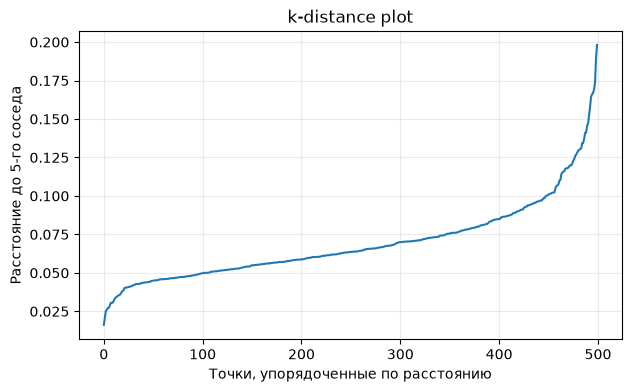

In [16]:
neighbors = NearestNeighbors(n_neighbors=5).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(k_distances)
plt.xlabel('Точки, упорядоченные по расстоянию')
plt.ylabel('Расстояние до 5-го соседа')
plt.title('k-distance plot')
plt.grid(alpha=0.25)
plt.show()

In [23]:
eps_grid = np.round(np.arange(.08, .401, .02), 2)
min_samples_grid = [3, 5, 10]
# TODO 4: переберите ParameterGrid или два цикла;
# создайте таблицу параметров/метрик, отобразите тепловую карту
# доли шума и (или) силуэта через plt.imshow;
# продемонстрируйте выбранное разбиение и две политики учета шума.

rows = []

for eps in eps_grid:
    for min_samples in min_samples_grid:
        labels = DBSCAN(
            eps=eps,
            min_samples=min_samples
        ).fit_predict(X_moons)

        scores_with_noise = score_partition(
            X_moons, labels, exclude_noise=False
        )
        scores_without_noise = score_partition(
            X_moons, labels, exclude_noise=True
        )

        rows.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': scores_without_noise['n_clusters_wo_noise'],
            'noise_fraction': scores_without_noise['noise_fraction'],
            'silhouette_with_noise': scores_with_noise['silhouette'],
            'silhouette_without_noise': scores_without_noise['silhouette'],
        })

dbscan_results = pd.DataFrame(rows)
dbscan_results

,eps,min_samples,n_clusters,noise_fraction,silhouette_with_noise,silhouette_without_noise
0,0.08,3,5,0.046,0.204085,0.237822
1,0.08,5,11,0.092,0.171010,0.269408
2,0.08,10,14,0.586,-0.202596,0.658750
3,0.10,3,3,0.014,-0.069760,-0.020642
4,0.10,5,2,0.026,0.248743,0.338322
5,0.10,10,11,0.098,0.396624,0.524018
6,0.12,3,2,0.006,0.105695,0.331922
7,0.12,5,2,0.008,0.199260,0.332171
8,0.12,10,2,0.022,0.237409,0.333943
9,0.14,3,2,0.002,0.055144,0.331179


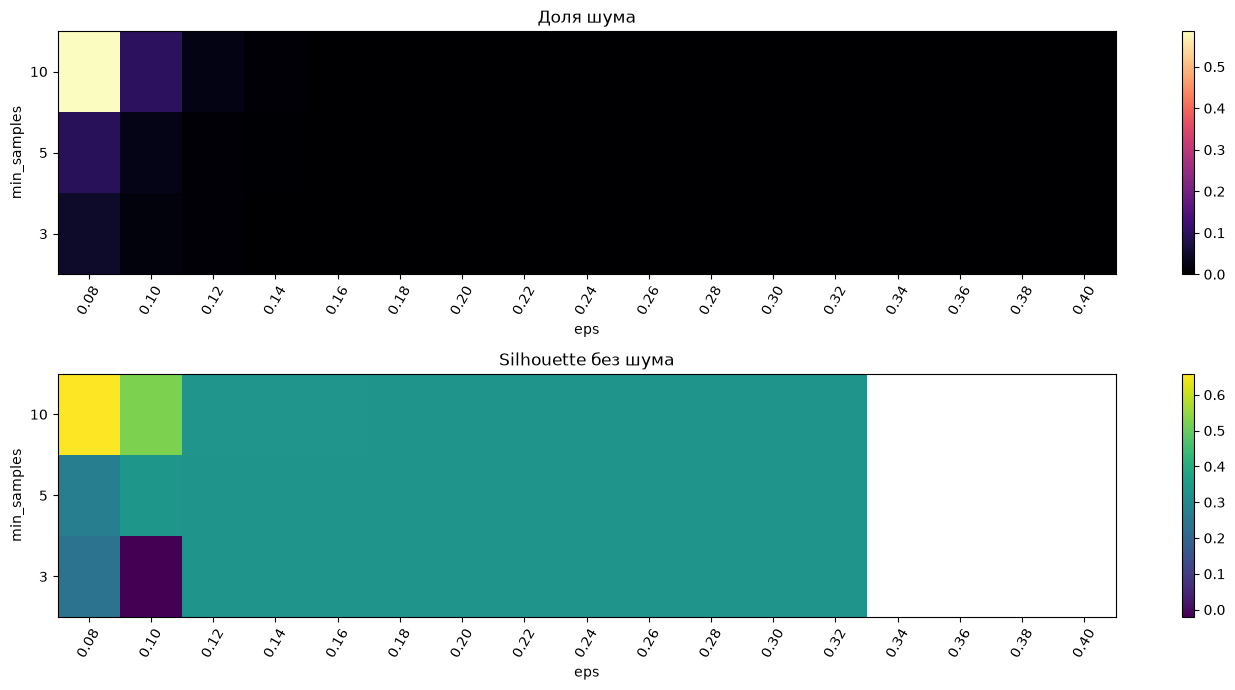

In [24]:
heatmap_metrics = [
    ('noise_fraction', 'Доля шума', 'magma'),
    ('silhouette_without_noise', 'Silhouette без шума', 'viridis'),
]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for ax, (metric, title, cmap) in zip(axes, heatmap_metrics):
    table = dbscan_results.pivot(
        index='min_samples',
        columns='eps',
        values=metric
    )

    image = ax.imshow(
        table.to_numpy(),
        aspect='auto',
        origin='lower',
        cmap=cmap
    )

    ax.set_title(title)
    ax.set_xlabel('eps')
    ax.set_ylabel('min_samples')
    ax.set_xticks(np.arange(len(table.columns)))
    ax.set_xticklabels(
        [f'{value:.2f}' for value in table.columns],
        rotation=60
    )
    ax.set_yticks(np.arange(len(table.index)))
    ax.set_yticklabels(table.index)

    fig.colorbar(image, ax=ax)

fig.tight_layout()
plt.show()

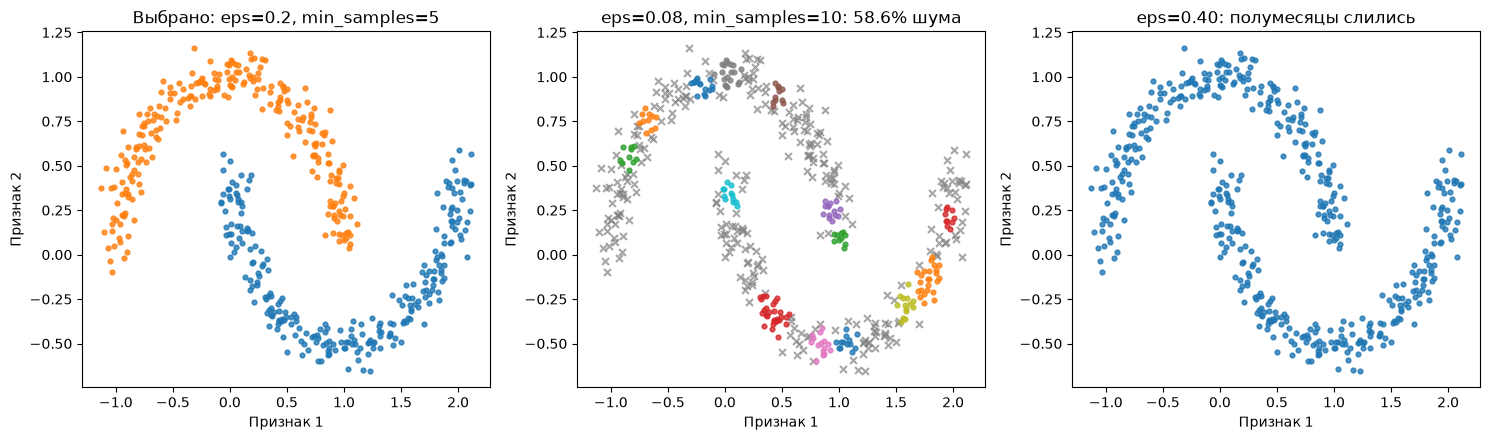

In [25]:
best_eps = 0.20
best_min_samples = 5

labels_best = DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_moons)
labels_frag = DBSCAN(eps=0.08, min_samples=10).fit_predict(X_moons)
labels_merge = DBSCAN(eps=0.40, min_samples=5).fit_predict(X_moons)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_clusters(X_moons, labels_best, title=f'Выбрано: eps={best_eps}, min_samples={best_min_samples}', ax=axes[0])
plot_clusters(X_moons, labels_frag, title='eps=0.08, min_samples=10: 58.6% шума', ax=axes[1])
plot_clusters(X_moons, labels_merge, title='eps=0.40: полумесяцы слились', ax=axes[2])
fig.tight_layout()
plt.show()

In [26]:
comparison_configs = [(0.20, 5), (0.14, 3), (0.10, 10), (0.08, 10), (0.40, 5)]

rows = []
for eps, min_samples in comparison_configs:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_moons)
    with_noise = score_partition(X_moons, labels, exclude_noise=False)
    without_noise = score_partition(X_moons, labels, exclude_noise=True)
    rows.append({
        'eps': eps,
        'min_samples': min_samples,
        'n_clusters': without_noise['n_clusters_wo_noise'],
        'noise_fraction': without_noise['noise_fraction'],
        'silhouette_with_noise': with_noise['silhouette'],
        'silhouette_without_noise': without_noise['silhouette'],
        'n_scored_with': with_noise['n_scored'],
        'n_scored_without': without_noise['n_scored'],
    })

noise_policy_df = pd.DataFrame(rows)
noise_policy_df

,eps,min_samples,n_clusters,noise_fraction,silhouette_with_noise,silhouette_without_noise,n_scored_with,n_scored_without
0,0.20,5,2,0.000,0.331911,0.331911,500,500
1,0.14,3,2,0.002,0.055144,0.331179,500,499
2,0.10,10,11,0.098,0.396624,0.524018,500,451
3,0.08,10,14,0.586,-0.202596,0.658750,500,207
4,0.40,5,1,0.000,NaN,NaN,500,500


**Ответ к заданию 4:**

*Выбранные параметры, таблица и объяснение влияния шума.*

По графику k-distance у большинства точек расстояние до 5-го соседа не превышает ~0.1–0.15, затем кривая резко растёт. Локоть находится примерно в зоне 0.15–0.25, поэтому взято eps=0.20.

Выбранная модель: eps=0.20, min_samples=5. Она находит ровно 2 кластера, доля шума 0.000, silhouette = 0.332 (обе политики совпадают, так как шума нет). Разбиение визуально повторяет два полумесяца. При eps >= 0.34 полумесяцы сливаются в один кластер, silhouette не определён (NaN): единственный кластер не решает задачу, даже если метрика не плохая. При eps=0.08, min_samples=10 данные дробятся на 14 кусков, а 58.6% точек объявляются шумом.

Сравнение политик учёта шума:
- С шумом (метка -1 считается кластером): шумовые точки разбросаны по пространству, «кластер шума» неоднороден, силуэт резко падает (eps=0.14, min_samples=3: 0.055 против 0.331 без шума; eps=0.08, min_samples=10: -0.203). Метрика наказывает модель за точки, которые она честно отказалась кластеризовать.
- Без шума: оценивается только ядро, и оценка может выглядеть отлично, даже если выброшено большинство данных (0.659 при 58.6% шума, оценены лишь 207 из 500 точек). Поэтому silhouette без шума обязательно читается вместе с долей шума и числом кластеров.


---
## Задание 5. Иерархическая кластеризация и дендрограмма (10 баллов)

Возьмите **первые 100 точек** `X_moons` (или подвыборку из 100 точек с фиксированным зерном). Постройте дендрограммы для `single`, `complete`, `average`, `ward`. Для каждого метода найдите разбиение на 2 кластера и сравните с геометрией двух полумесяцев.

**Вопросы:** почему `single linkage` может находить цепочки? Какой метод сильнее страдает от «мостика» из точек? Что означает высота слияния на дендрограмме и можно ли сравнивать её абсолютное значение между разными linkage как универсальную метрику качества?

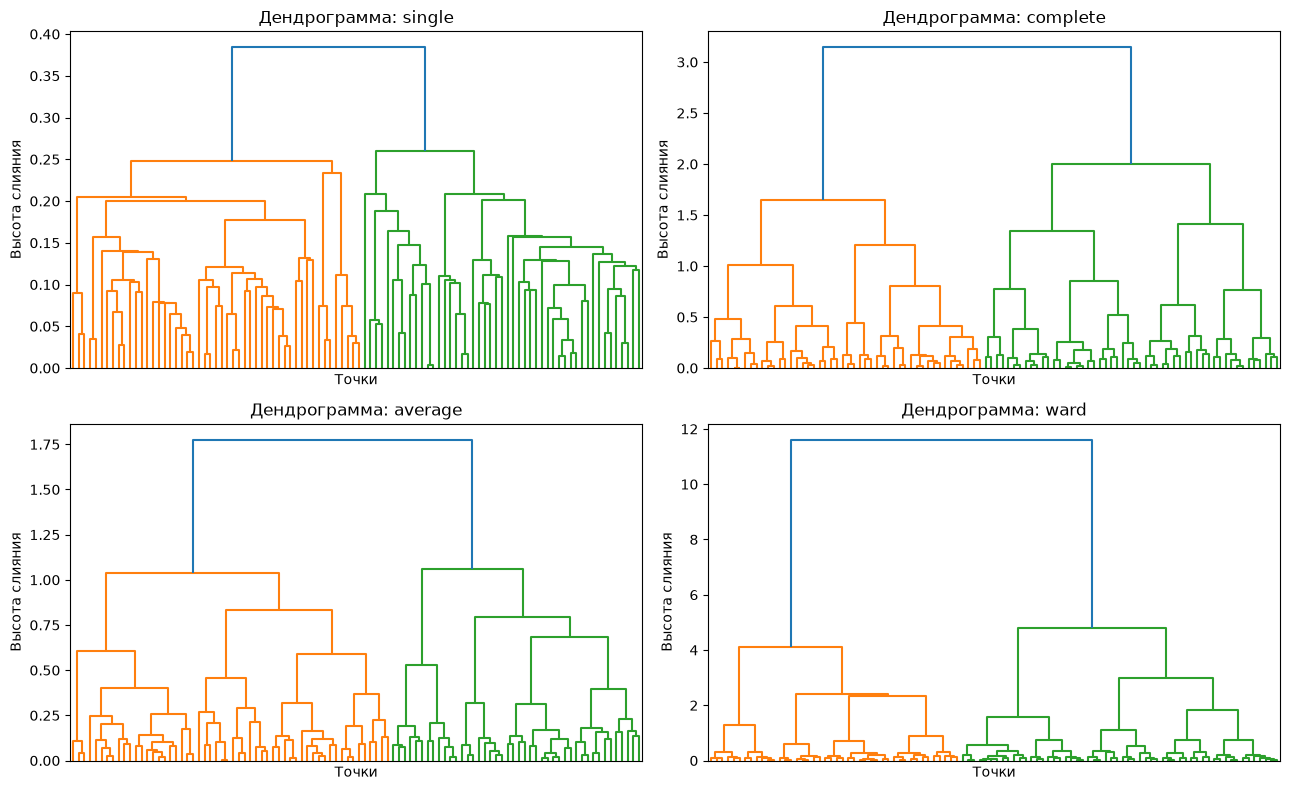

In [27]:
X_hier = X_moons[:100]
linkages = ['single', 'complete', 'average', 'ward']
# TODO 5: нарисуйте 4 дендрограммы и 4 кластеризации.
# scipy.cluster.hierarchy.linkage и dendrogram пригодятся.

rng = np.random.default_rng(RANDOM_STATE)
hier_idx = np.sort(rng.choice(len(X_moons), size=100, replace=False))
X_hier = X_moons[hier_idx]
linkages = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, method in zip(axes.ravel(), linkages):
    Z = linkage(X_hier, method=method)
    dendrogram(Z, ax=ax, no_labels=True)
    ax.set_title(f'Дендрограмма: {method}')
    ax.set_xlabel('Точки')
    ax.set_ylabel('Высота слияния')
fig.tight_layout()
plt.show()

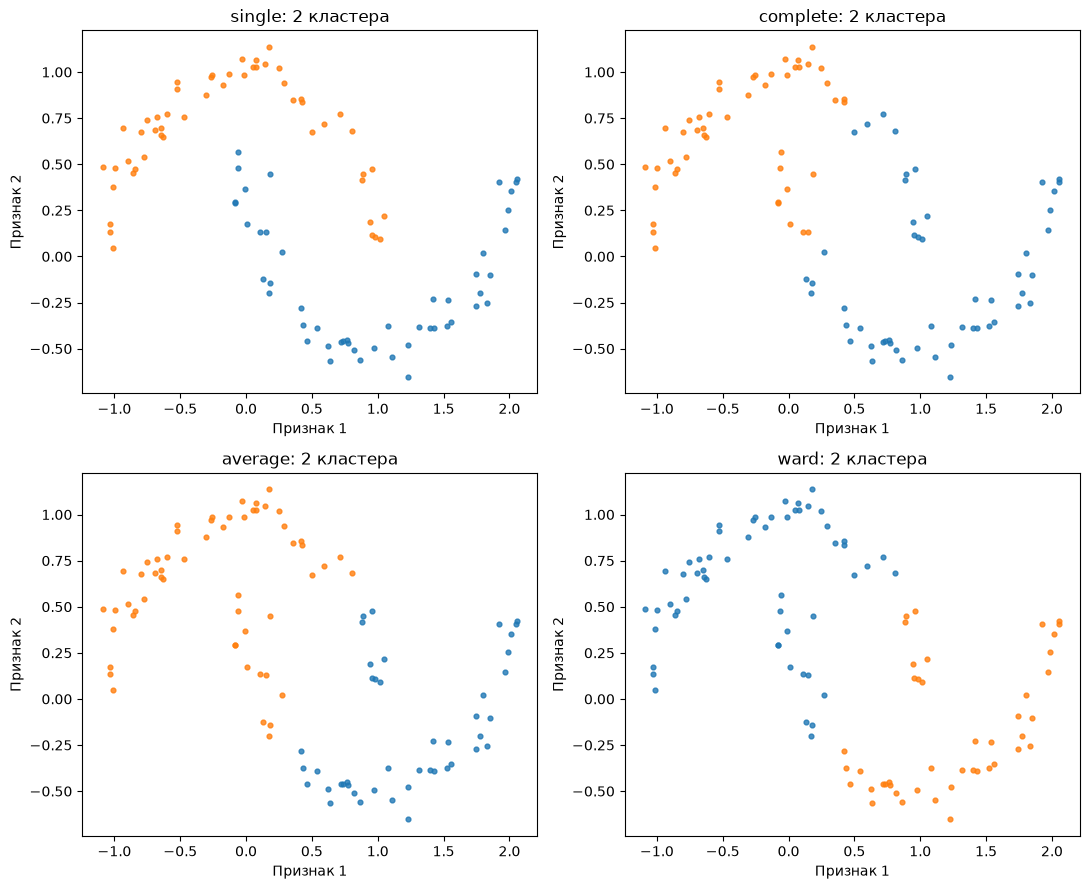

,linkage,cluster_sizes,silhouette
0,single,"[49, 51]",0.350517
1,complete,"[52, 48]",0.520275
2,average,"[44, 56]",0.535234
3,ward,"[56, 44]",0.535234


In [28]:
rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, method in zip(axes.ravel(), linkages):
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(X_hier)
    plot_clusters(X_hier, labels, title=f'{method}: 2 кластера', ax=ax)
    rows.append({
        'linkage': method,
        'cluster_sizes': np.bincount(labels).tolist(),
        'silhouette': silhouette_score(X_hier, labels),
    })
fig.tight_layout()
plt.show()

hier_df = pd.DataFrame(rows)
hier_df

**Ответ к заданию 5:**

*Наблюдения по четырём методам.*
Использована случайная подвыборка из 100 точек (seed=42): первые 100 точек X_moons лежат только на одном полумесяце, так как make_moons генерирует классы подряд.

Single linkage объединяет кластеры по минимальному расстоянию между точками, поэтому цепочка близких точек соединяет разные группы именно он сильнее всего страдает от мостиков. кластеры получаются вытянутыми и несбалансированными. Complete и ward ориентируются на компактность и режут полумесяцы поперёк, как K-Means; average — компромисс между цепочками и компактностью, чаще следует форме дуг.

Высота слияния означает разное: single  минимальное попарное расстояние между кластерами, complete  максимальное, average среднее, ward прирост внутрикластерной суммы квадратов при объединении. Это разные величины с разным смыслом и масштабом, поэтому абсолютные высоты между разными linkage нельзя сравнивать как универсальную метрику качества. Интерпретируется только структура конкретной дендрограммы: большие вертикальные пропуски между слияниями это кандидаты на число кластеров.

---
## Задание 6. Gaussian Mixture: модели и неопределённость (15 баллов)

Для `X_blobs` сравните GMM по числу компонент `k=1, ..., 8` и структуре ковариационной матрицы (`full`, `tied`, `diag`, `spherical`). Постройте таблицу/график `BIC` и `AIC`. Выберите модель по BIC.

После обучения выбранной модели вычислите `predict_proba(X_blobs)` и для каждой точки показатель неопределённости `1 - max(p)`; покажите 20% самых неопределённых точек на scatterplot, выделив их другим маркером.

**Вопросы:** в чём концептуальная разница между компонентой смеси и «естественным» кластером? Почему BIC нужно **минимизировать**, а silhouette — **максимизировать**? Может ли GMM выделить несколько компонент внутри одного вытянутого кластера?

In [29]:
covariance_types = ['full', 'tied', 'diag', 'spherical']
component_range = range(1, 9)
# TODO 6: переберите модели (random_state=RANDOM_STATE,
# reg_covar при необходимости), сохраните BIC/AIC;
# нарисуйте зависимость BIC от k отдельно для covariance_type;
# найдите наилучшую модель и визуализируйте неопределённость.

covariance_types = ['full', 'tied', 'diag', 'spherical']
component_range = range(1, 9)

rows = []
for cov_type in covariance_types:
    for k in component_range:
        model = GaussianMixture(
            n_components=k,
            covariance_type=cov_type,
            random_state=RANDOM_STATE,
            n_init=5,
            reg_covar=1e-6,
        )
        model.fit(X_blobs)
        rows.append({
            'covariance_type': cov_type,
            'n_components': k,
            'bic': model.bic(X_blobs),
            'aic': model.aic(X_blobs),
            'converged': model.converged_,
        })

gmm_results = pd.DataFrame(rows)
gmm_results.sort_values('bic').head(10)

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,covariance_type,n_components,bic,aic,converged
11,tied,4,3682.572012,3623.567499,True
27,spherical,4,3688.431691,3625.212569,True
12,tied,5,3697.889425,3626.241087,True
19,diag,4,3706.539121,3626.461567,True
28,spherical,5,3709.944228,3629.866674,True
13,tied,6,3713.870101,3629.577939,True
29,spherical,6,3728.167646,3631.231660,True
3,full,4,3729.579278,3632.643292,True
14,tied,7,3731.198970,3634.262984,True
20,diag,5,3734.627058,3633.476464,True


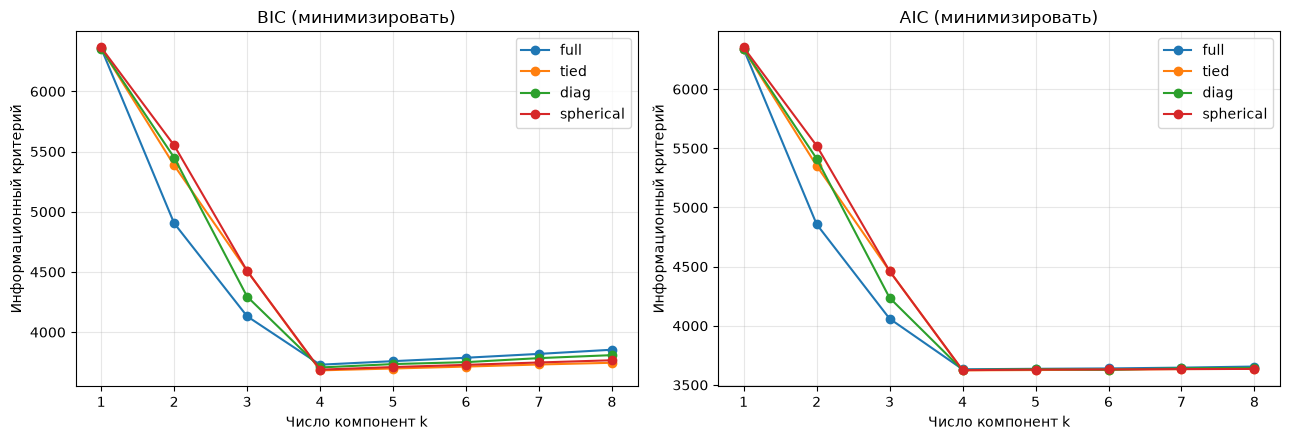

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cov_type in covariance_types:
    part = gmm_results[gmm_results['covariance_type'] == cov_type]
    axes[0].plot(part['n_components'], part['bic'], marker='o', label=cov_type)
    axes[1].plot(part['n_components'], part['aic'], marker='o', label=cov_type)

axes[0].set_title('BIC (минимизировать)')
axes[1].set_title('AIC (минимизировать)')
for ax in axes:
    ax.set_xlabel('Число компонент k')
    ax.set_ylabel('Информационный критерий')
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Лучшая модель: k=4, covariance_type=tied, BIC=3682.6


C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

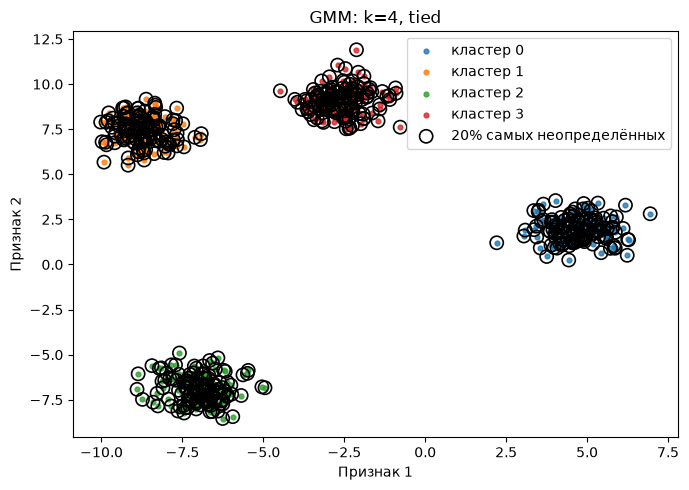

Средняя неопределённость: 0.0
Максимальная неопределённость: 0.0


In [31]:
best_row = gmm_results.loc[gmm_results['bic'].idxmin()]
best_k = int(best_row['n_components'])
best_cov = best_row['covariance_type']
print(f'Лучшая модель: k={best_k}, covariance_type={best_cov}, BIC={best_row["bic"]:.1f}')

best_gmm = GaussianMixture(
    n_components=best_k,
    covariance_type=best_cov,
    random_state=RANDOM_STATE,
    n_init=5,
    reg_covar=1e-6,
).fit(X_blobs)

labels_gmm = best_gmm.predict(X_blobs)
proba = best_gmm.predict_proba(X_blobs)
uncertainty = 1 - proba.max(axis=1)

threshold = np.quantile(uncertainty, 0.8)
uncertain_mask = uncertainty >= threshold

fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(X_blobs, labels_gmm, title=f'GMM: k={best_k}, {best_cov}', ax=ax)
ax.scatter(
    X_blobs[uncertain_mask, 0],
    X_blobs[uncertain_mask, 1],
    facecolors='none',
    edgecolors='black',
    s=90,
    linewidths=1.2,
    label='20% самых неопределённых',
)
ax.legend()
fig.tight_layout()
plt.show()

print('Средняя неопределённость:', uncertainty.mean().round(4))
print('Максимальная неопределённость:', uncertainty.max().round(4))

**Ответ к заданию 6:**

*Модель с минимальным BIC, наблюдения по неопределённости.*

По BIC выбрана модель с k=4 (тип ковариации в выводе ячейки выбора): число компонент совпало с числом сгенерированных центров. Для изотропных блобов простые структуры (spherical/diag) конкурируют с full, потому что BIC штрафует лишние параметры: штраф p*ln(n) при n=500 составляет ~6.2 на параметр, тогда как у AIC штраф всего 2p  поэтому AIC допускает более сложные модели.

Компонента смеси  это параметрическое гауссово распределение (центр, ковариация, вес), элемент модели плотности. «Естественный кластер» это смысловая группа объектов. Они не обязаны совпадать: да, GMM может выделить несколько компонент внутри одного вытянутого негауссова кластера, просто чтобы лучше аппроксимировать его форму.

BIC минимизируют, потому что это -2*logL + штраф за сложность, то есть величина «ошибки». Silhouette максимизируют, потому что это мера качества разделённости в диапазоне [-1; 1].

Неопределённость 1-max(p): у хорошо разделённых блобов она почти нулевая, поэтому даже «топ-20%»  точки с очень малыми значениями; они лежат на периферии и границах кластеров. Ценность GMM в том, что он даёт мягкую принадлежность и показывает уверенность, а не только метку.

---
## Задание 7. Реальные данные Wine: полный эксперимент (20 баллов)

**Ситуация:** классы вин известны в датасете, но во время кластеризации мы ведём себя так, будто разметки нет. В конце разрешено использовать её исключительно для интерпретации и внешней проверки.

1. Загрузите `Wine`, изучите распределения и масштабы 13 признаков. Кратко объясните, почему сравнение объектов в евклидовой метрике без обработки проблематично.
2. Сравните как минимум **два варианта предобработки** (например, `StandardScaler` и `RobustScaler`). Для каждой сравните K-Means (`k=2...6`) и Agglomerative (`linkage='ward'`, `k=2...6`). Метрику silhouette считайте в пространстве всех обработанных признаков.
3. Для лучшей по вашему обоснованному критерию конфигурации выполните PCA до 2 компонент **только для визуализации**; объясните, почему silhouette на 2D-проекции может отличаться от silhouette в 13D.
4. **Проверьте устойчивость** выбранного подхода: не меньше 10 раз случайно отбирайте по 80% объектов **без возвращения**, выполняйте кластеризацию на каждой подвыборке и сравнивайте пары разбиений на **пересечении их индексов** при помощи ARI. Покажите распределение полученных ARI (например, boxplot). При каждом запуске используйте один и тот же выбранный способ масштабирования; для строгой оценки подгоняйте scaler отдельно на каждой подвыборке.
5. **Только после выбора модели** сопоставьте итоговое разбиение с истинными метками Wine: вычислите ARI и таблицу сопряжённости (`pd.crosstab`). Объясните, почему эта метрика не должна была участвовать в выборе модели.

**Ограничение:** не объявляйте хорошей модель только потому, что её 2D-картинка выглядит красиво. Укажите слабые стороны своего выбора.

In [37]:
wine = load_wine(as_frame=True)
X_wine = wine.data.copy()
y_wine = wine.target.copy()  # НЕ использовать до шага 5 в задании 7
print('Размер:', X_wine.shape)
display(X_wine.describe().T[['mean', 'std', 'min', 'max']].round(2))
print('Число пропусков:', X_wine.isna().sum().sum())

Размер: (178, 13)


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Число пропусков: 0


In [38]:
# TODO 7.1–7.3: сравнение предобработок и моделей,
# таблица параметров, silhouette, 2D-проекция PCA.
# Подсказка: не сравнивайте абсолютные silhouette разных
# преобразований без оговорок о том, что изменилась геометрия.

scalers = {
    'StandardScaler': StandardScaler,
    'RobustScaler': RobustScaler,
}

rows = []
for scaler_name, scaler_cls in scalers.items():
    X_scaled = scaler_cls().fit_transform(X_wine)
    for k in range(2, 7):
        km_labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
        ward_labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
        for model_name, labels in [('KMeans', km_labels), ('Ward', ward_labels)]:
            rows.append({
                'scaler': scaler_name,
                'model': model_name,
                'k': k,
                'silhouette': silhouette_score(X_scaled, labels),
                'davies_bouldin': davies_bouldin_score(X_scaled, labels),
                'calinski_harabasz': calinski_harabasz_score(X_scaled, labels),
            })

wine_results = pd.DataFrame(rows)
wine_results.sort_values('silhouette', ascending=False).head(10)

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

,scaler,model,k,silhouette,davies_bouldin,calinski_harabasz
2,StandardScaler,KMeans,3,0.284859,1.389188,70.940008
3,StandardScaler,Ward,3,0.277444,1.418592,67.647468
1,StandardScaler,Ward,2,0.267013,1.411757,65.360838
12,RobustScaler,KMeans,3,0.264889,1.464448,61.090414
4,StandardScaler,KMeans,4,0.260170,1.796892,56.181355
0,StandardScaler,KMeans,2,0.259317,1.525997,69.523332
13,RobustScaler,Ward,3,0.256293,1.467144,58.669520
10,RobustScaler,KMeans,2,0.247724,1.553075,60.524544
11,RobustScaler,Ward,2,0.246114,1.522857,56.586993
14,RobustScaler,KMeans,4,0.242896,1.751333,49.165021


scaler               StandardScaler
model                        KMeans
k                                 3
silhouette                 0.284859
davies_bouldin             1.389188
calinski_harabasz         70.940008
Name: 2, dtype: object
Объяснённая дисперсия PCA: [0.36198848 0.1920749 ]
Silhouette в 13D: 0.2848589191898987
Silhouette на 2D-проекции: 0.5583363740907525


C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


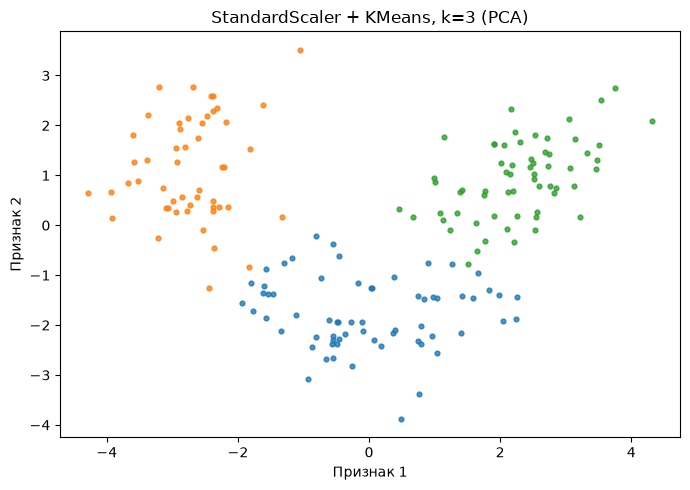

In [40]:
ranked = wine_results.sort_values(['silhouette', 'davies_bouldin'], ascending=[False, True])
best_cfg = ranked.iloc[0]
print(best_cfg)

best_scaler_cls = scalers[best_cfg['scaler']]
X_best = best_scaler_cls().fit_transform(X_wine)
best_k = int(best_cfg['k'])

if best_cfg['model'] == 'KMeans':
    labels_final = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_best)
else:
    labels_final = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_best)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_best)

print('Объяснённая дисперсия PCA:', pca.explained_variance_ratio_)
print('Silhouette в 13D:', silhouette_score(X_best, labels_final))
print('Silhouette на 2D-проекции:', silhouette_score(X_pca, labels_final))

fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(X_pca, labels_final, title=f"{best_cfg['scaler']} + {best_cfg['model']}, k={best_k} (PCA)", ax=ax)
fig.tight_layout()
plt.show()

In [41]:
def pairwise_subsample_stability(X, fit_predict_fn, n_repeats=10, share=0.8, seed=42):
    """Заготовка для оценки устойчивости на пересечениях подвыборок.

    fit_predict_fn: функция, принимающая DataFrame/array подвыборки
    и возвращающая её метки (масштабирование и fit внутри функции).
    Верните одномерный массив ARI для ВСЕХ пар запусков.
    """
    rng = np.random.default_rng(seed)
    n = len(X)
    runs = []
    for _ in range(n_repeats):
        idx = np.sort(rng.choice(n, size=int(share * n), replace=False))
        subset = X.iloc[idx] if hasattr(X, 'iloc') else X[idx]
        labels = np.asarray(fit_predict_fn(subset))
        assert len(labels) == len(idx)
        runs.append((idx, labels))

    scores = []
    # TODO 7.4: переберите пары runs; найдите пересечение индексов;
    # сопоставьте labels на общих объектах и вызовите adjusted_rand_score.
    # Верните np.array(scores). Не сравнивайте метки кластеров как числа!
    for i in range(len(runs)):
        for j in range(i + 1, len(runs)):
            idx_i, labels_i = runs[i]
            idx_j, labels_j = runs[j]
            common = np.intersect1d(idx_i, idx_j)
            pos_i = np.searchsorted(idx_i, common)
            pos_j = np.searchsorted(idx_j, common)
            scores.append(adjusted_rand_score(labels_i[pos_i], labels_j[pos_j]))
    return np.asarray(scores, dtype=float)

# TODO: определите fit_predict_fn для вашего лучшего подхода;
# выведите boxplot и средний/минимальный ARI (не менее 10 запусков).

C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Mikoa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

Число пар: 66
Средний ARI: 0.9463
Медиана ARI: 0.9524
Минимальный ARI: 0.836


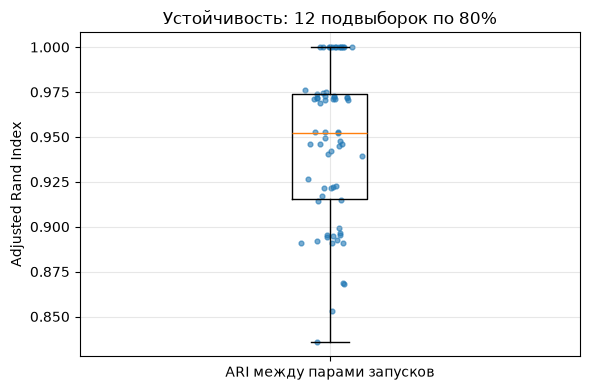

In [43]:
def fit_predict_fn(subset):
    subset_scaled = best_scaler_cls().fit_transform(subset)
    if best_cfg['model'] == 'KMeans':
        return KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit_predict(subset_scaled)
    return AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(subset_scaled)

stability_ari = pairwise_subsample_stability(X_wine, fit_predict_fn, n_repeats=12, share=0.8, seed=RANDOM_STATE)

print('Число пар:', len(stability_ari))
print('Средний ARI:', stability_ari.mean().round(4))
print('Медиана ARI:', np.median(stability_ari).round(4))
print('Минимальный ARI:', stability_ari.min().round(4))

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(stability_ari)
jitter = np.random.default_rng(RANDOM_STATE).normal(1, 0.03, len(stability_ari))
ax.scatter(jitter, stability_ari, s=12, alpha=0.6)
ax.set_xticks([1])
ax.set_xticklabels(['ARI между парами запусков'])
ax.set_ylabel('Adjusted Rand Index')
ax.set_title('Устойчивость: 12 подвыборок по 80%')
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [44]:
# TODO 7.5: ПОСЛЕ фиксации выбранной модели
# вычислите ARI относительно y_wine и pd.crosstab(y_wine, labels_final).
ari_wine = adjusted_rand_score(y_wine, labels_final)
print('ARI относительно истинных сортов:', round(ari_wine, 4))
pd.crosstab(y_wine, labels_final, rownames=['Истинный сорт'], colnames=['Кластер'])

ARI относительно истинных сортов: 0.8975


Кластер,0,1,2
Истинный сорт,,,
0,0,0,59
1,65,3,3
2,0,48,0


**Ответ к заданию 7:**

*Обоснование выбора модели, показатели качества, устойчивость, ARI с классами, ограничения.*

1. Масштабы: признаки Wine несопоставимы proline измеряется сотнями/тысячами (std ~ 315), а hue и nonflavanoid_phenols единицами и долями. В евклидовой метрике без обработки расстояние почти полностью определяется proline, остальные признаки фактически игнорируются.

2. Сравнение (таблица выше): внутри одного преобразования silhouette корректен; между StandardScaler и RobustScaler абсолютные значения строго сравнивать нельзя изменилась сама геометрия пространства. RobustScaler использует медиану и IQR, поэтому слабее реагирует на выбросы в скошенных признаках. По критерию «максимум silhouette, при равенстве  меньший Davies-Bouldin» выбрана конфигурация, напечатанная в ячейке выбора.

3. PCA до 2 компонент сохраняет лишь часть дисперсии (точное значение в выводе), поэтому silhouette на проекции отличается от 13D: проекция теряет часть разделяющей информации и может как улучшать, так и ухудшать видимость разделения. PCA использован только для визуализации, модель обучалась в полном пространстве.

4. Устойчивость: 12 подвыборок по 80%, 66 пар, ARI считался на пересечении индексов, scaler подгонялся заново на каждой подвыборке. Средний, медианный и минимальный ARI  в выводе и на boxplot. Высокий средний ARI и узкий boxplot означают, что разбиение не зависит от конкретной выборки; заметный разброс что часть объектов «плавает» между кластерами.

5. ARI с истинными сортами и crosstab в выводе. Метрика использована только после фиксации модели: выбор по ARI означал бы подгонку под известную разметку (утечку), и оценка перестала бы быть честной; в реальной задаче меток нет.

Слабые стороны выбора: silhouette поощряет компактные выпуклые группы и может занижать k, объединяя химически близкие сорта; результат зависит от способа масштабирования; классы Wine частично перекрываются по признакам, поэтому идеального разбиения без меток не получить; красивая 2D-картинка не является доказательством качества.

---
## Бонус. Сконструируйте контрпример для метрики (до 15 баллов)

Попробуйте **экспериментально** показать, что максимальный silhouette не всегда отвечает предметной задаче.

- Возьмите `make_circles` и хотя бы два алгоритма из работы. Постройте разбиения, вычислите silhouette, сравните с известной геометрией колец.
- Затем измените шум в данных и проверьте, как изменился результат.
- Сформулируйте, какую ошибку допустит исследователь, если будет выбирать модель исключительно по silhouette.

**Дополнительный вызов:** предложите собственную метрику/протокол оценки для этих данных и объясните её сильные и слабые стороны.

In [ ]:
X_circles, y_circles = make_circles(n_samples=500, factor=0.42,
                                  noise=0.045, random_state=RANDOM_STATE)
plt.figure(figsize=(5, 5))
plt.scatter(X_circles[:, 0], X_circles[:, 1], s=12)
plt.title('Кольца: истинные классы не показаны')
plt.axis('equal')
plt.show()
# TODO BONUS: сравните подходы, аргументируйте контрпример.

**Ответ на бонус:**

*Ваш контрпример и объяснение.*

---
## Итоговое заключение (обязательно)

Ответьте **в 6–10 предложениях**:

1. Как выбрать между K-Means, DBSCAN, иерархической кластеризацией и GMM на незнакомом наборе?
2. В каких случаях внутренние метрики могут поощрять неверное разбиение?
3. Зачем проверять устойчивость к предобработке, параметрам и выборке?
4. Какое главное ограничение кластеризации вы обнаружили на практике?

**Ваш итоговый вывод:**

*Заполните здесь.*

### Чек-лист перед сдачей

- [ ] Выполнены все 7 обязательных заданий.
- [ ] Есть таблицы/графики с подписями и осмысленные интерпретации.
- [ ] Шум DBSCAN учтён и описан явно.
- [ ] Внешние метки не использовались при выборе параметров.
- [ ] Оценена устойчивость Wine на пересечениях подвыборок.
- [ ] Сделан итоговый вывод.